<a href="https://colab.research.google.com/github/Maurofome/Lab01_EDA_Aliaga_Mauricio/blob/main/Lab2_8_RLineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import kagglehub, os
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(path))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']


Paso 0: Configuración

In [31]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def metricas(y, y_pred):
    return {"R2": round(r2_score(y, y_pred), 4),
            "MAE": round(mean_absolute_error(y, y_pred), 4),
            "RMSE": round(float(np.sqrt(mean_squared_error(y, y_pred))), 4)}

Bloque 1: Breast Cancer
1.1 Carga e inspección

In [32]:
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(path))
df = pd.read_csv(os.path.join(path, "data.csv"))
print(df.shape)
print(df.dtypes.value_counts())
print(df.isna().sum().sort_values().tail(3))
df = df.drop(columns=["id", "Unnamed: 32"])

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']
(569, 33)
float64    31
int64       1
object      1
Name: count, dtype: int64
symmetry_worst               0
fractal_dimension_worst      0
Unnamed: 32                569
dtype: int64


## Bloque 1: Regresión lineal simple

Carga y descarte de columnas
El dataset tiene 569 filas y 33 columnas. Descarté "id" porque es solo un identificador y no una medición, y "Unnamed: 32" porque está completamente vacía. "diagnosis" es categórica y no la uso en los modelos, porque no es una medición de los núcleos celulares.

1.2 EDA

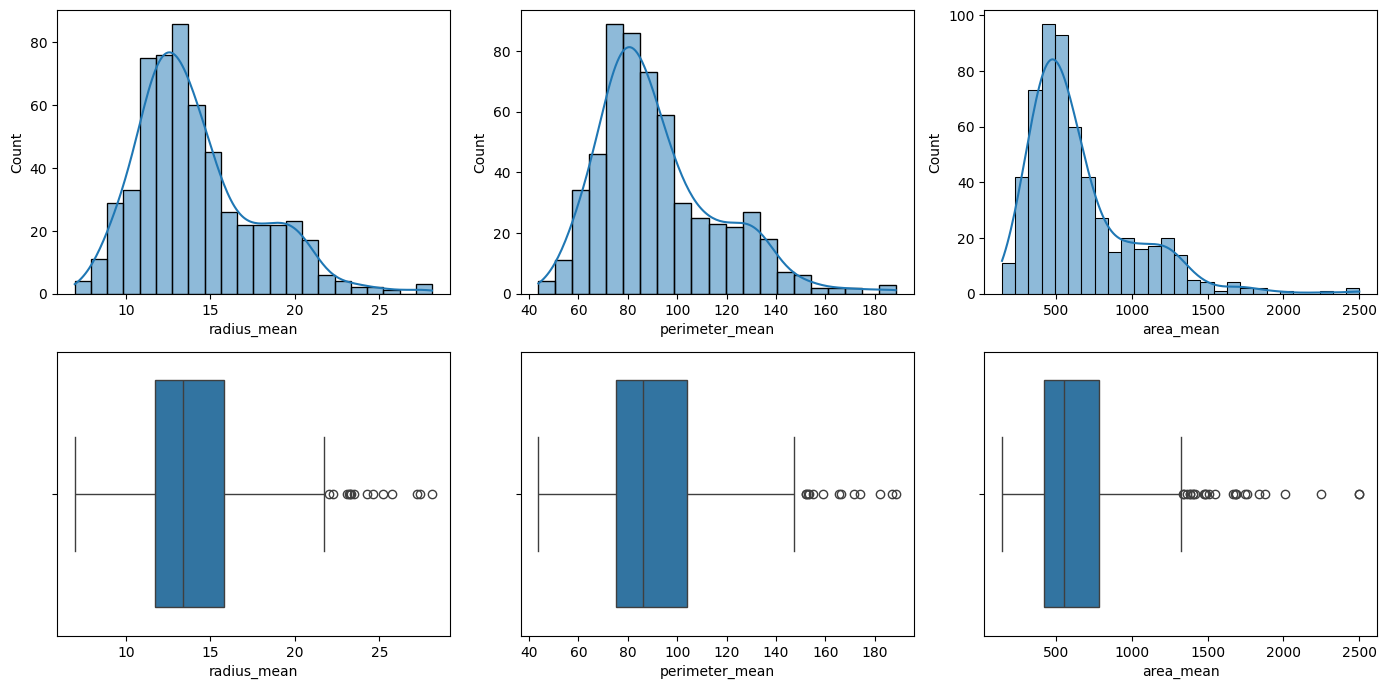

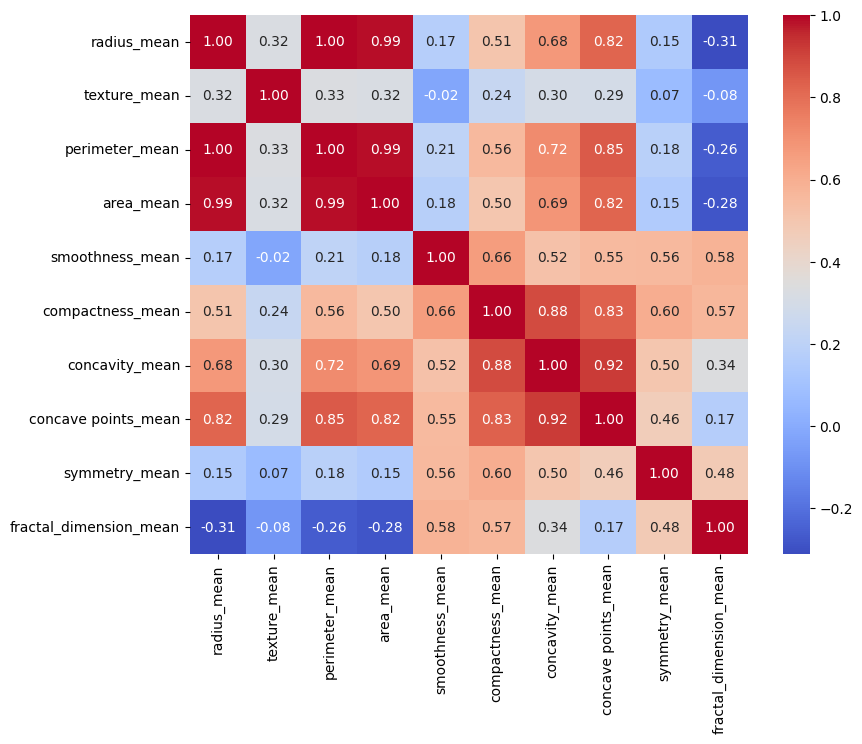

In [33]:
vars1 = ["radius_mean", "perimeter_mean", "area_mean"]

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, v in enumerate(vars1):
    sns.histplot(df[v], kde=True, ax=ax[0, i])
    sns.boxplot(x=df[v], ax=ax[1, i])
plt.tight_layout(); plt.show()

mean_cols = [c for c in df.columns if c.endswith("_mean")]
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

### EDA
Las distribuciones de las tres variables están sesgadas a la derecha y los box-plots muestran algunos valores atípicos en los núcleos más grandes. No los eliminé porque son mediciones reales. En el mapa de correlaciones, "radius_mean", "perimeter_mean" y "area_mean" están casi perfectamente correlacionadas (≈ {0.99}), lo que tiene sentido porque las tres miden el tamaño del núcleo. Por eso trabajo con estas variables.

1.3 Modelos, métricas y gráficos

perimeter_mean = 6.864 * radius_mean + -5.021
Test: {'R2': 0.9957, 'MAE': 1.0424, 'RMSE': 1.5834}


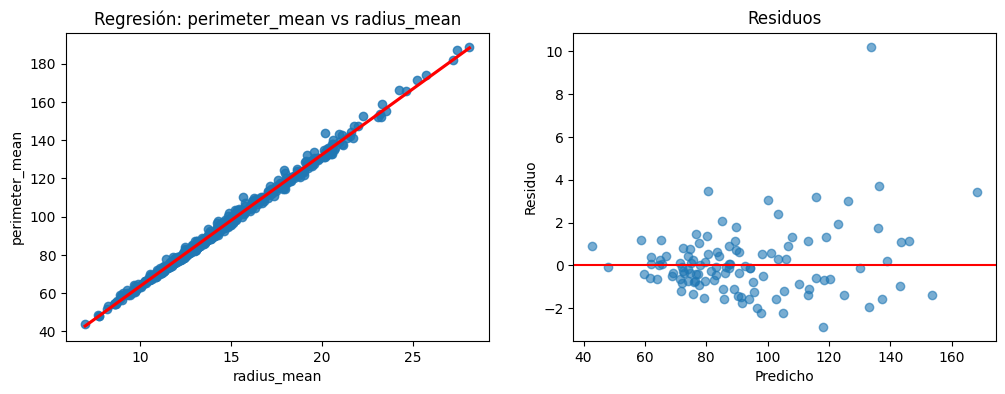

area_mean = 99.041 * radius_mean + -743.845
Test: {'R2': 0.9812, 'MAE': 34.9748, 'RMSE': 46.5776}


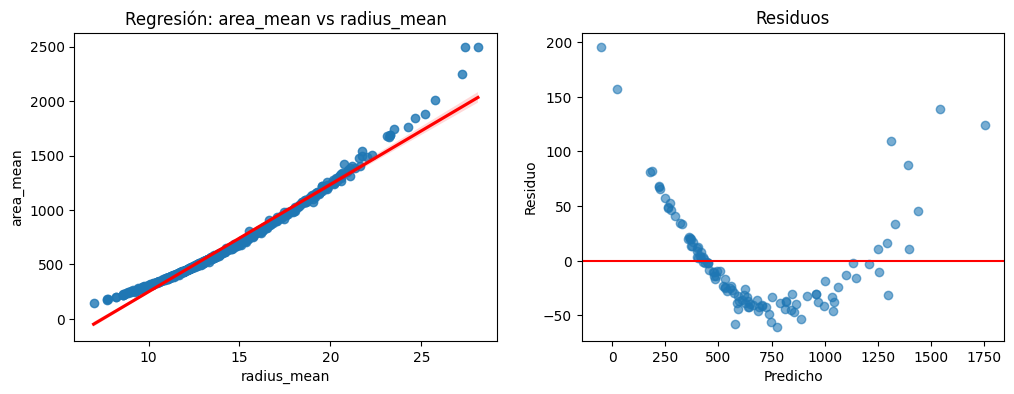

In [34]:
def modelo_simple(df, x, y):
    X_tr, X_te, y_tr, y_te = train_test_split(df[[x]], df[y], test_size=0.2, random_state=42)
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    print(f"{y} = {m.coef_[0]:.3f} * {x} + {m.intercept_:.3f}")
    print("Test:", metricas(y_te, pred))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.regplot(x=df[x], y=df[y], line_kws={"color": "red"}, ax=ax[0])
    ax[0].set_title(f"Regresión: {y} vs {x}")
    ax[1].scatter(pred, y_te - pred, alpha=.6)
    ax[1].axhline(0, color="red")
    ax[1].set(xlabel="Predicho", ylabel="Residuo", title="Residuos")
    plt.show()

modelo_simple(df, "radius_mean", "perimeter_mean")   # Modelo 1
modelo_simple(df, "radius_mean", "area_mean")        # Modelo 2

Modelo 1: perimeter_mean ~ radius_mean

-Pendiente = {X}:** por cada unidad que aumenta el radio, el perímetro aumenta en promedio {X} unidades. Es coherente con la geometría: el perímetro de un círculo es 2πr (≈ 6,28 veces el radio).

-Intercepto = {Y}:** es el perímetro esperado con radio 0. No tiene interpretación práctica (no existe un núcleo de radio 0), solo ajusta la recta a los datos.
-Métricas (test):** R² = {X}, MAE = {X}, RMSE = {X}.

Modelo 2: area_mean ~ radius_mean

-Pendiente = {X}:** por cada unidad que aumenta el radio, el área aumenta en promedio {X} unidades. Es solo un promedio, porque el área crece con r² y no de forma lineal.

-Intercepto = {Y}:** es el área esperada con radio 0; tampoco tiene sentido práctico y compensa la forma curva de la relación.
-Métricas (test):** R² = {X}, MAE = {X}, RMSE = {X}.

¿Un R² alto basta para concluir que una recta es adecuada?
No. Ambos modelos tienen R² alto (perímetro: {X}, área: {Y}), pero los residuos cuentan algo distinto. En el modelo del perímetro, los residuos se reparten al azar alrededor de 0, así que la recta es adecuada. En el modelo del área, los residuos forman una curva (en forma de U), lo que indica que la relación no es lineal sino cuadrática: la recta se equivoca de forma sistemática en los extremos aunque el R² sea alto. Por eso hay que revisar los residuos y no solo el R².

BLOQUE 2: FIFA 19
2.1 Carga y correlaciones

In [35]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [36]:
path = kagglehub.dataset_download("javagarm/fifa-19-complete-player-dataset")
archivo = os.path.join(path, "kl.csv")

for enc in ["utf-8", "cp1252", "latin-1"]:
    try:
        fifa = pd.read_csv(archivo, encoding=enc)
        print("Codificación que funcionó:", enc)
        break
    except UnicodeDecodeError:
        continue

print(fifa.shape)

# Debe imprimir [] si están todas las columnas
necesarias = ["Overall", "Position", "Reactions", "Composure", "ShortPassing",
              "BallControl", "Vision", "Age", "Stamina", "Strength"]
print([c for c in necesarias if c not in fifa.columns])

corr = (fifa.select_dtypes("number").corr()["Overall"]
        .drop("Overall").sort_values(key=abs, ascending=False))
print(corr.head(20))

Using Colab cache for faster access to the 'fifa-19-complete-player-dataset' dataset.
Codificación que funcionó: cp1252
(18207, 89)
[]
Unnamed: 0                 -0.972848
Reactions                   0.849987
Composure                   0.727725
Potential                   0.660732
Special                     0.607336
ShortPassing                0.503013
International Reputation    0.499087
Vision                      0.498859
LongPassing                 0.484186
BallControl                 0.460847
Age                         0.452486
ShotPower                   0.441647
LongShots                   0.421313
Curve                       0.419933
ID                         -0.417023
Skill Moves                 0.414950
FKAccuracy                  0.397365
Aggression                  0.395728
Crossing                    0.395472
Volleys                     0.391780
Name: Overall, dtype: float64


Bloque 2: Regresión lineal múltiple (FIFA 19)

El dataset indicado en la guía (`karangadiya/fifa19`) ya no está disponible en Kaggle, por lo que usé la copia `javagarm/fifa-19-complete-player-dataset`, que contiene {X} jugadores y {Y} columnas.

Carga y correlaciones
La variable objetivo es `Overall` (valoración general del jugador). Calculé la correlación de todas las variables numéricas con `Overall` para identificar las de mayor importancia: las más correlacionadas son {Reactions ({X}), Composure ({X}), …}.

2.2 Selección de predictores y EDA

(18145, 10)


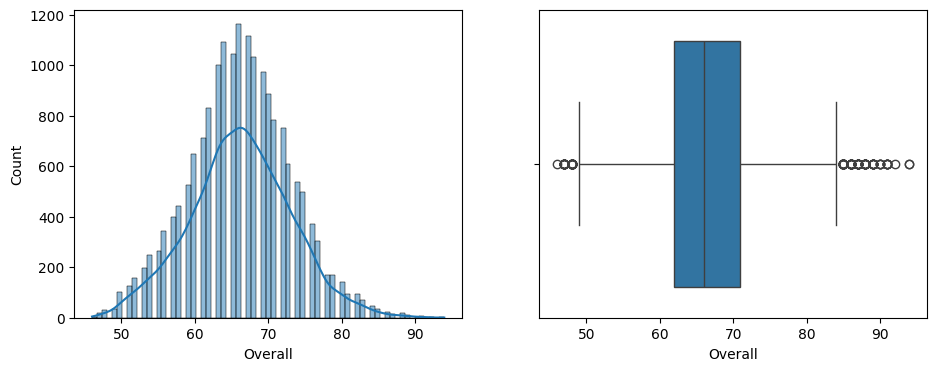

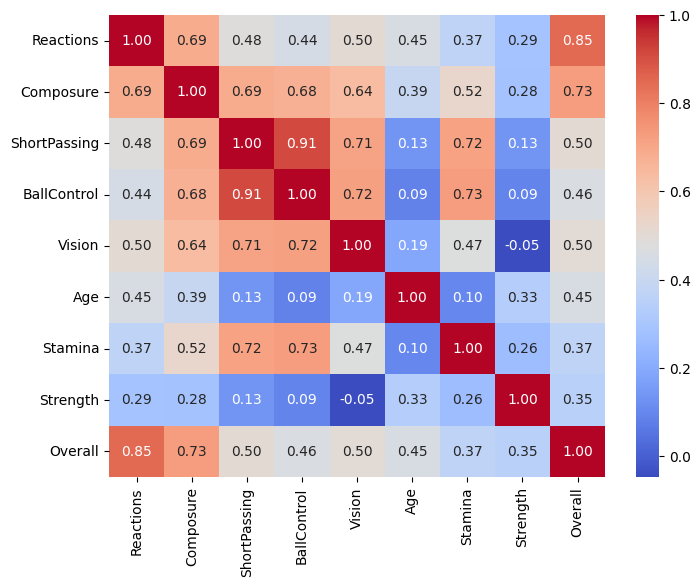

In [37]:
preds = ["Reactions", "Composure", "ShortPassing", "BallControl", "Vision", "Age", "Stamina", "Strength"]
d = fifa[preds + ["Overall", "Position"]].dropna()
print(d.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(d["Overall"], kde=True, ax=ax[0])
sns.boxplot(x=d["Overall"], ax=ax[1])
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(d[preds + ["Overall"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

EDA
La variable objetivo `Overall` tiene una distribución {aproximadamente simétrica, centrada en ≈ {X}} y algunos valores atípicos hacia los jugadores de élite. En el gráfico de correlaciones, las variables más relacionadas con Overall son {Reactions ({X}), Composure ({X}), …}, por lo que las elegí como candidatas, junto con `Age`, `Stamina`, `Strength` y `Vision`.

Predictores descartados (pregunta de control de leakage)
- `Value`, `Wage` y `Release Clause`: son consecuencia del Overall (el mercado paga según la calidad del jugador); no existirían antes de conocerlo.
- `Special` y las columnas de rating por posición (`LS`, `ST`, `RW`, etc.): se calculan con los mismos atributos que definen el Overall, es decir, provienen de la misma fuente.
- `Potential`: es una estimación de la misma fuente y duplica casi por completo al Overall.

Predictores mantenidos: {lista final}. Son atributos individuales medibles (técnicos, físicos y mentales) que existen antes de calcular la valoración general.

2.3 Multicolinealidad (VIF)

In [38]:
def vif(cols):
    X = add_constant(d[cols])
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=cols).round(2)

print(vif(preds))

Reactions       2.13
Composure       3.17
ShortPassing    6.70
BallControl     7.26
Vision          2.65
Age             1.44
Stamina         2.42
Strength        1.39
dtype: float64


In [39]:
quitar = []        # ej: ["ShortPassing"]
preds = [p for p in preds if p not in quitar]
print(vif(preds))

Reactions       2.13
Composure       3.17
ShortPassing    6.70
BallControl     7.26
Vision          2.65
Age             1.44
Stamina         2.42
Strength        1.39
dtype: float64


Multicolinealidad
En la matriz de correlación y el VIF, {variables} tuvieron VIF de {X}, sobre el umbral de 5–10, porque miden habilidades técnicas muy parecidas y aportan información redundante. Eliminé {variable} y recalculé: todas quedaron bajo {Y}. Mantuve las demás porque aportan información distinta.

2.4 Modelo, métricas y gráficos

Train: {'R2': 0.7759, 'MAE': 2.5841, 'RMSE': 3.2811}
Test:  {'R2': 0.7631, 'MAE': 2.603, 'RMSE': 3.3215}
Reactions       0.485
Composure       0.143
ShortPassing    0.032
BallControl    -0.012
Vision          0.016
Age             0.047
Stamina        -0.030
Strength        0.059
dtype: float64
Intercepto: 22.628


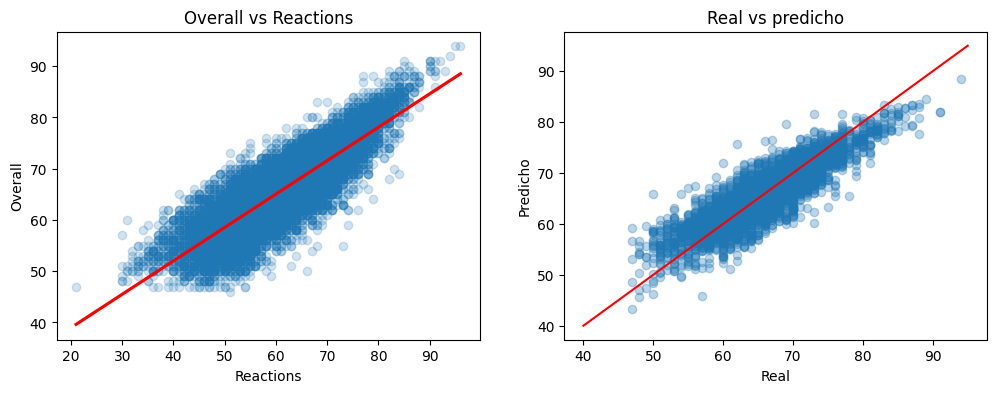

In [40]:
X_tr, X_te, y_tr, y_te = train_test_split(d[preds], d["Overall"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_tr, y_tr)
pred = m.predict(X_te)

print("Train:", metricas(y_tr, m.predict(X_tr)))
print("Test: ", metricas(y_te, pred))
print(pd.Series(m.coef_, index=preds).round(3))
print("Intercepto:", round(m.intercept_, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(x=d["Reactions"], y=d["Overall"], scatter_kws={"alpha": .2}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title("Overall vs Reactions")
ax[1].scatter(y_te, pred, alpha=.3)
ax[1].plot([40, 95], [40, 95], "r")
ax[1].set(xlabel="Real", ylabel="Predicho", title="Real vs predicho")
plt.show()

Métricas
- Entrenamiento: R² = {X}, MAE = {X}, RMSE = {X}
- Prueba: R² = {X}, MAE = {X}, RMSE = {X}

Los valores de entrenamiento y prueba son muy parecidos, así que el modelo generaliza bien y no hay sobreajuste. En promedio, el modelo se equivoca en unos {MAE} puntos de Overall. En el gráfico real vs. predicho, los puntos siguen la diagonal, lo que confirma un buen ajuste.
Interpretación de coeficientes (elige 3 de tu salida)
- Reactions = {X}:** por cada punto adicional de Reactions, el Overall sube en promedio {X} puntos, manteniendo las demás variables constantes. Es la variable de mayor peso, coherente con su alta correlación con Overall.
- Age = {X}:** por cada año más de edad, el Overall cambia en {X} puntos, con el resto constante.
- Strength = {X}:** por cada punto más de fuerza, el Overall cambia en {X} puntos; su efecto es pequeño comparado con Reactions.

2.5 Heterogeneidad

Arquero 394 {'R2': 0.6876, 'MAE': 3.2503, 'RMSE': 4.032}
Jugador de campo 3235 {'R2': 0.7722, 'MAE': 2.5242, 'RMSE': 3.2243}


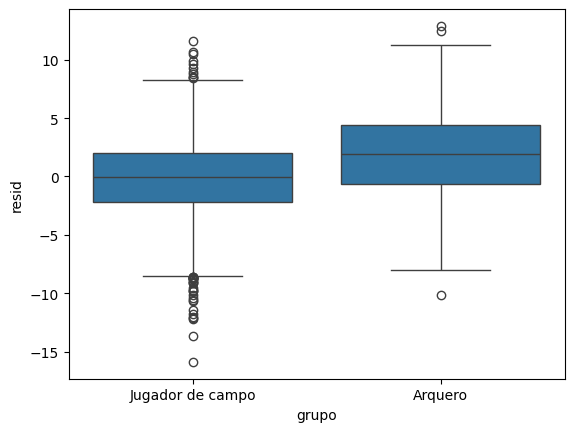

In [41]:
res = d.loc[X_te.index].copy()
res["pred"] = pred
res["resid"] = res["Overall"] - res["pred"]
res["grupo"] = np.where(res["Position"] == "GK", "Arquero", "Jugador de campo")

for g, sub in res.groupby("grupo"):
    print(g, len(sub), metricas(sub["Overall"], sub["pred"]))

sns.boxplot(data=res, x="grupo", y="resid")
plt.show()

Heterogeneidad
Dividí a los jugadores en arqueros y jugadores de campo.
- Jugadores de campo: R² = {X}, MAE = {X}, RMSE = {X}
- Arqueros: R² = {Y}, MAE = {Y}, RMSE = {Y}

El modelo {funciona peor / tiene más error} en arqueros, porque sus atributos clave (reflejos, estiramiento, colocación) no están entre mis predictores, y los que sí usé (pases, control de balón) casi no los describen. En el box-plot de residuos se ve que los arqueros tienen {residuos sesgados hacia un lado / mayor dispersión}. Un solo modelo global esconde esta diferencia dentro del error promedio.

BLOQUE 3: Student Performance
3.1 Carga y selección

In [42]:
path = kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")
df3 = pd.read_csv(os.path.join(path, "student_performance_dataset.csv"))
print(df3.shape)

objetivo = "final_exam_score"
preds3 = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade"]
segmento = "gender"

d3 = df3[preds3 + [objetivo, segmento]].dropna()
print(d3.shape)
print(d3.describe().round(2))

Using Colab cache for faster access to the 'student-performance-and-study-habits-dataset' dataset.
(1000, 12)
(1000, 6)
       study_time_hours  attendance_percent  sleep_hours  previous_grade  \
count           1000.00             1000.00       1000.0         1000.00   
mean               3.57               85.09          6.8           69.74   
std                1.48                9.27          1.2           12.61   
min                0.50               54.80          3.2           31.30   
25%                2.60               78.80          5.9           61.00   
50%                3.60               85.20          6.8           69.60   
75%                4.50               91.90          7.6           78.40   
max                8.10              100.00         10.0          100.00   

       final_exam_score  
count           1000.00  
mean              83.54  
std               10.34  
min               46.80  
25%               76.07  
50%               83.80  
75%          

Bloque 3: Mi dataset (Student Performance & Study Habits)

Nota: El dataset es simulado (según su descripción en Kaggle), por lo que los resultados reflejan relaciones construidas y no necesariamente datos reales de estudiantes.

Variable objetivo y predictores
El dataset tiene {1000} filas y {12} columnas. Elegí `final_exam_score` como variable objetivo porque es numérica continua. Descarté:
- `student_id`: es solo un identificador, no aporta información.
- `final_grade`: es la nota en letra y se calcula a partir del puntaje del examen, es decir, es consecuencia directa de la variable objetivo (leakage).
- Las variables categóricas (`parental_education`, `internet_access`, etc.): las dejé fuera para mantener un modelo simple con predictores numéricos. `parental_education` además tiene {102} valores nulos.

Mantuve `study_time_hours`, `attendance_percent`, `sleep_hours` y `previous_grade`, porque son variables que existen antes de rendir el examen final. En particular, `previous_grade` es una nota anterior al examen, así que no es consecuencia de él.

3.2 EDA

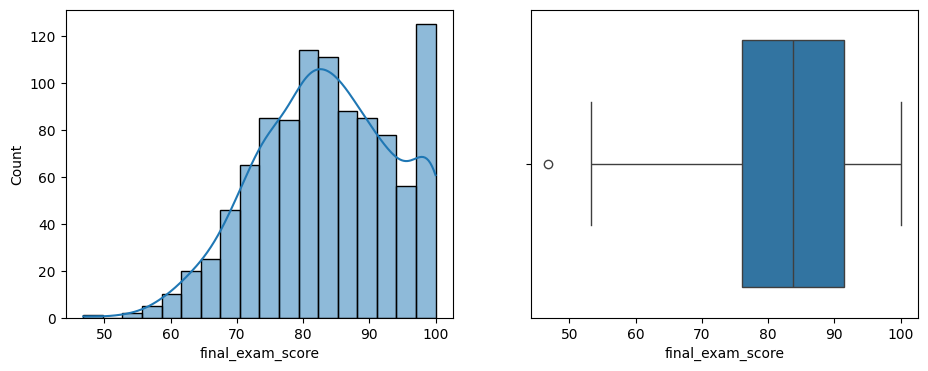

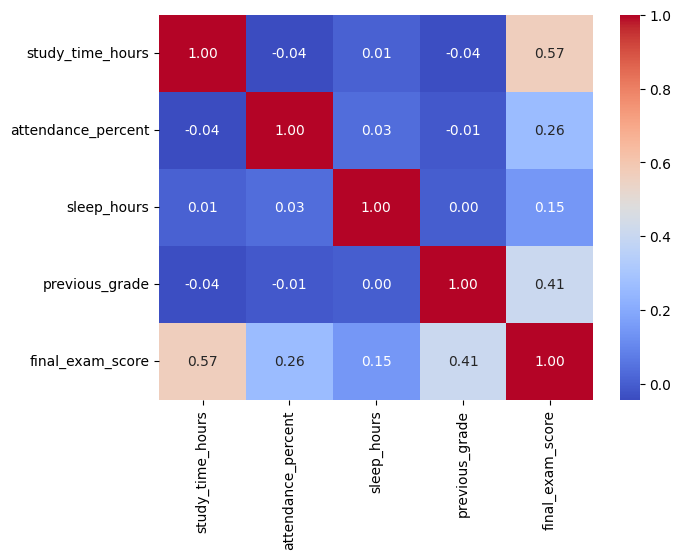

Predictor más correlacionado: study_time_hours


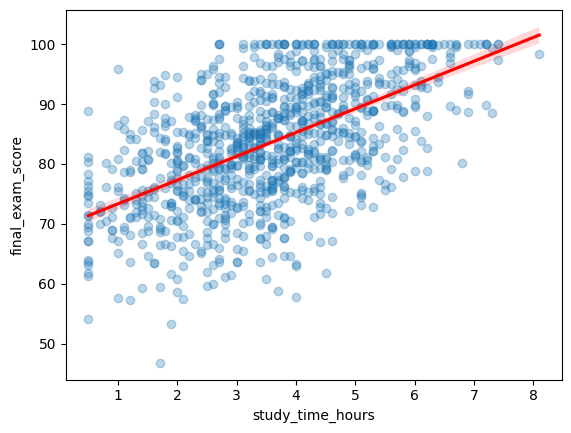

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(d3[objetivo], kde=True, ax=ax[0])
sns.boxplot(x=d3[objetivo], ax=ax[1])
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(d3[preds3 + [objetivo]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

mejor = d3[preds3].corrwith(d3[objetivo]).abs().idxmax()
print("Predictor más correlacionado:", mejor)
sns.regplot(x=d3[mejor], y=d3[objetivo], scatter_kws={"alpha": .3}, line_kws={"color": "red"})
plt.show()

EDA
La variable `final_exam_score` tiene una distribución {describe: forma, centro ≈ X, si hay acumulación en 100}. El box-plot {muestra / no muestra} valores atípicos. En el gráfico de correlaciones, las variables más relacionadas con la nota del examen son {previous_grade ({X}), study_time_hours ({X}), …}, y {sleep_hours} tiene una relación {débil}. El gráfico de regresión del predictor más correlacionado, `{mejor}`, muestra una relación {positiva y aproximadamente lineal / con mucha dispersión}.

3.3 Multicolinealidad (VIF)

In [44]:
X = add_constant(d3[preds3])
print(pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                index=preds3).round(2))

study_time_hours      1.0
attendance_percent    1.0
sleep_hours           1.0
previous_grade        1.0
dtype: float64


Multicolinealidad
En la matriz de correlación, los predictores {no están fuertemente correlacionados entre sí / {A} y {B} tienen correlación de {X}}. Los VIF son {todos menores a 5 (máximo {X})}, por lo que no hay multicolinealidad relevante y mantuve los cuatro predictores.

3.4 Modelo y métricas

In [45]:
X_tr, X_te, y_tr, y_te = train_test_split(d3[preds3], d3[objetivo], test_size=0.2, random_state=42)
m3 = LinearRegression().fit(X_tr, y_tr)
pred3 = m3.predict(X_te)

print("Train:", metricas(y_tr, m3.predict(X_tr)))
print("Test: ", metricas(y_te, pred3))
print(pd.Series(m3.coef_, index=preds3).round(3))
print("Intercepto:", round(m3.intercept_, 3))

Train: {'R2': 0.6044, 'MAE': 5.1286, 'RMSE': 6.479}
Test:  {'R2': 0.6146, 'MAE': 4.9989, 'RMSE': 6.4406}
study_time_hours      4.137
attendance_percent    0.324
sleep_hours           1.050
previous_grade        0.351
dtype: float64
Intercepto: 9.784


Modelo y métricas
- Entrenamiento: R² = {X}, MAE = {X}, RMSE = {X}
- Prueba: R² = {X}, MAE = {X}, RMSE = {X}

El modelo explica aproximadamente el {X} % de la variación de la nota del examen. En promedio, se equivoca en unos {MAE} puntos de la escala de 0 a 100.

3.5 Residuos

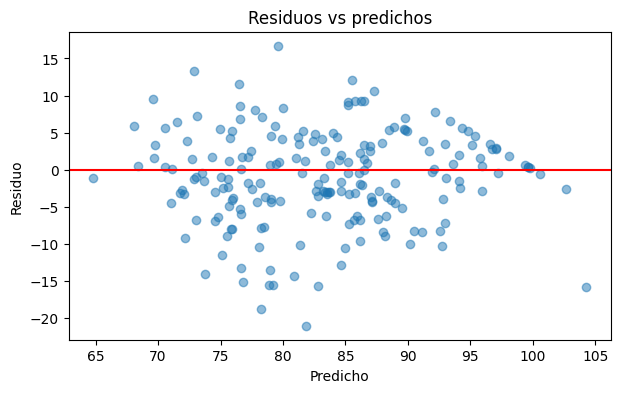

In [46]:
plt.figure(figsize=(7, 4))
plt.scatter(pred3, y_te - pred3, alpha=.5)
plt.axhline(0, color="red")
plt.xlabel("Predicho"); plt.ylabel("Residuo"); plt.title("Residuos vs predichos")
plt.show()

3.6 Heterogeneidad

Female 105 {'R2': 0.638, 'MAE': 4.951, 'RMSE': 6.2275}
Male 95 {'R2': 0.5855, 'MAE': 5.0519, 'RMSE': 6.6682}


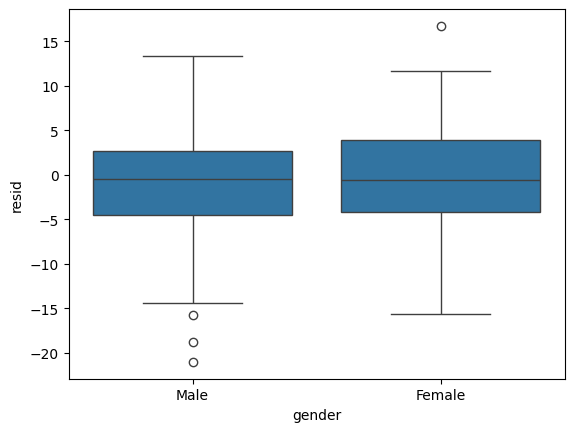

In [47]:
r = d3.loc[X_te.index].copy()
r["pred"] = pred3
r["resid"] = r[objetivo] - r["pred"]

for g, sub in r.groupby(segmento):
    print(g, len(sub), metricas(sub[objetivo], sub["pred"]))

sns.boxplot(data=r, x=segmento, y="resid")
plt.show()

Heterogeneidad
Segmenté por `gender`.
- {Female}: R² = {X}, MAE = {X}, RMSE = {X}
- {Male}: R² = {Y}, MAE = {Y}, RMSE = {Y}

El modelo {funciona de forma similar en ambos grupos / tiene más error en {grupo}}. Los residuos de ambos grupos {están centrados en 0 y con dispersión parecida / difieren en {sesgo o dispersión}}. Esto indica que {una sola recta describe bien a ambos grupos / el error promedio esconde una diferencia entre grupos}.

Preguntas de cierre

Interpretación de un coeficiente: El coeficiente de `study_time_hours` es {X}: por cada hora adicional de estudio, la nota del examen final cambia en promedio {X} puntos (en la escala de 0 a 100), manteniendo constantes asistencia, horas de sueño y nota anterior.

Error en entrenamiento vs. prueba: El RMSE en entrenamiento ({X}) y en prueba ({Y}) son {muy parecidos}. Esto indica que el modelo generaliza bien a datos nuevos y no hay sobreajuste. {Si el de prueba fuera bastante mayor, indicaría sobreajuste.}

Supuesto de la regresión: El modelo {cumple / incumple} el supuesto de {varianza constante de los residuos (homocedasticidad) / linealidad}. En el gráfico de residuos vs. predichos, {los puntos se reparten al azar alrededor de 0 con dispersión uniforme, lo que respalda el supuesto / se observa {una curva o un patrón en los valores altos, probablemente porque las notas se acumulan en el tope de 100}, lo que contradice el supuesto}.